Otsu threshold: 135.0


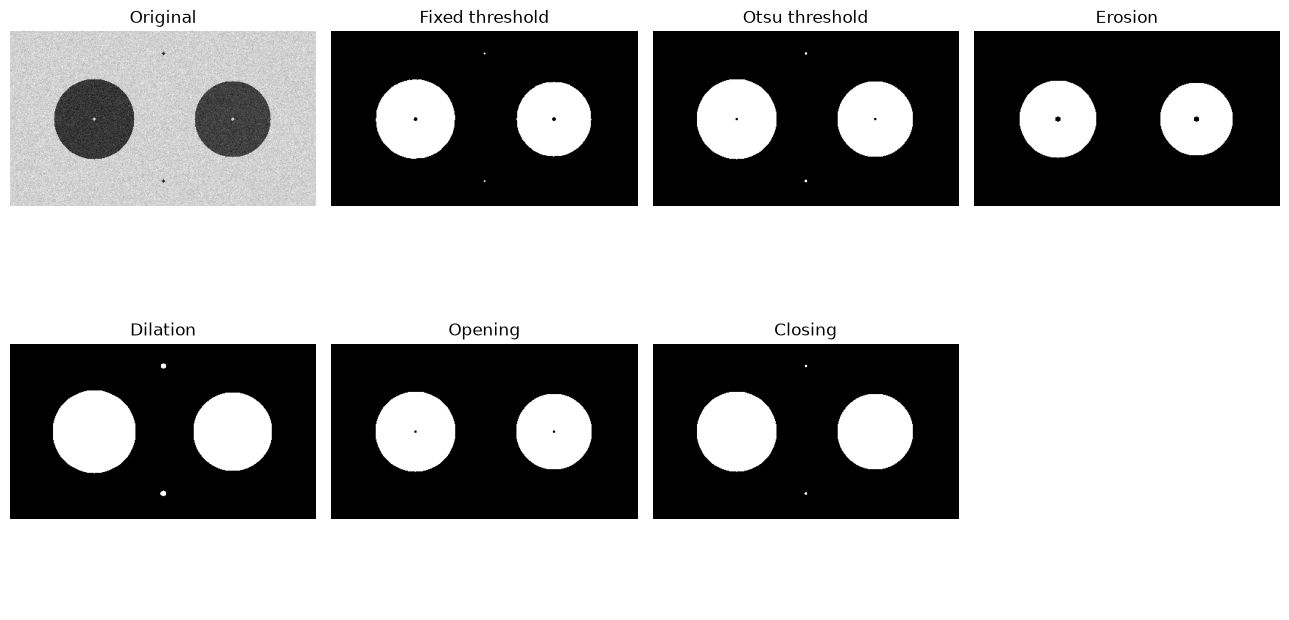

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a synthetic grayscale image
img = np.full((240, 420,), 210, dtype=np.uint8)

# Two dark foreground objects
cv2.circle(img, (115, 120), 55, 55, -1)
cv2.circle(img, (305, 120), 52, 65, -1)

# Add small bright holes in the dark objects
cv2.circle(img, (115, 120), 2, 210, -1)
cv2.circle(img, (305, 120), 2, 210, -1)

# Add isolated dark specks
cv2.circle(img, (210, 30), 2, 40, -1)
cv2.circle(img, (210, 205), 2, 40, -1)

# Add reproducible image noise
rng = np.random.default_rng(7)
noise = rng.normal(0, 14, img.shape)

img = np.clip(
    img.astype(np.float32) + noise,
    0, 255
).astype(np.uint8)

# Smooth before thresholding
blurred = cv2.GaussianBlur(img, (5, 5), 0)

# Fixed global threshold
_, fixed = cv2.threshold(
    blurred, 100, 255, cv2.THRESH_BINARY_INV
)

# Automatic Otsu threshold
otsu_value, mask = cv2.threshold(
    blurred, 0, 255,
    cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU
)

# Morphological structuring element
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

eroded = cv2.erode(mask, kernel, iterations=1)

dilated = cv2.dilate(mask, kernel, iterations=1)

opened = cv2.morphologyEx(
    mask, cv2.MORPH_OPEN, kernel
)

closed = cv2.morphologyEx(
    mask, cv2.MORPH_CLOSE, kernel
)

print("Otsu threshold:", otsu_value)

# Display all stages for classroom comparison
images = [
    ("Original", img),
    ("Fixed threshold", fixed),
        ("Otsu threshold", mask),
    ("Erosion", eroded),
    ("Dilation", dilated),
    ("Opening", opened),
    ("Closing", closed),
]

fig, axes = plt.subplots(2, 4, figsize=(13, 7))

for ax, (title, image) in zip(axes.flat, images):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

for ax in axes.flat[len(images):]:
    ax.axis("off")
    
plt.tight_layout()
plt.show()
